In [ ]:

from google.colab import files

uploaded = files.upload()



Saving 05_kpis_by_customer_segment.csv.xls to 05_kpis_by_customer_segment.csv.xls
Saving 04_balance_sheet.csv.xls to 04_balance_sheet.csv.xls
Saving 03_income_statement_standalone.csv.xls to 03_income_statement_standalone.csv.xls
Saving 02_loans_and_deposits.csv.xls to 02_loans_and_deposits.csv.xls
Saving 01b_segment_totals_reconciliation.csv.xls to 01b_segment_totals_reconciliation.csv.xls
Saving 01_segment_profitability.csv.xls to 01_segment_profitability.csv.xls
Saving 00_data_dictionary.csv.xls to 00_data_dictionary.csv.xls


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import glob


profit = load_data("01_segment_profitability")
loans = load_data("02_loans_and_deposits")


print("Profitability columns:")
print(profit.columns.tolist())

print("\nLoans and deposits columns:")
print(loans.columns.tolist())

Profitability columns:
['entity', 'period', 'period_type', 'period_end', 'balance_sheet_date', 'segment', 'parent_segment', 'is_subsegment', 'segment_revenue_cr', 'segment_pbt_cr', 'segment_assets_cr', 'segment_liabilities_cr', 'net_funding_position_cr', 'pbt_margin_pct', 'annualized_pbt_to_segment_assets_pct', 'liabilities_to_assets_x', 'share_of_entity_pbt_pct', 'share_of_entity_revenue_pct', 'share_of_entity_assets_pct', 'share_of_entity_liabilities_pct', 'source_file', 'source_page', 'segment_revenue_yoy_pct', 'segment_revenue_qoq_pct', 'segment_pbt_yoy_pct', 'segment_pbt_qoq_pct']

Loans and deposits columns:
['category', 'customer_segment', 'line_item', 'jun_2025_cr', 'jun_2026_cr', 'abs_change_cr', 'yoy_growth_pct', 'reported_yoy_growth_pct', 'source_file', 'source_page', 'share_of_category_jun_2026_pct', 'share_of_category_jun_2025_pct']


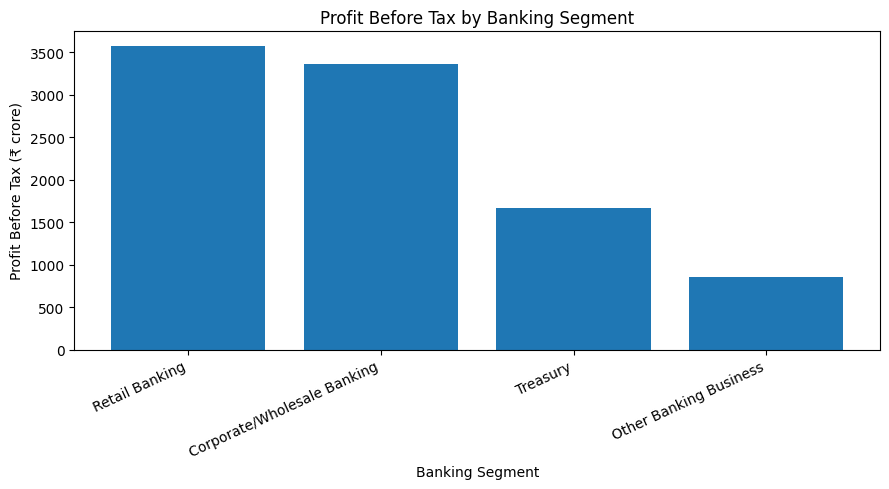

                       segment  segment_revenue_cr  segment_pbt_cr  \
2               Retail Banking            38269.30         3565.52   
1  Corporate/Wholesale Banking            14167.50         3358.26   
0                     Treasury             8487.17         1663.85   
5       Other Banking Business              915.57          848.93   

   pbt_margin_pct  
2            9.32  
1           23.70  
0           19.60  
5           92.72  


In [ ]:
q1 = profit[
    (profit["entity"] == "Standalone") &
    (profit["period"] == "Q1FY27") &
    (profit["is_subsegment"] == False) &
    (profit["segment"] != "Unallocated")
].copy()

q1 = q1.sort_values("segment_pbt_cr", ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(q1["segment"], q1["segment_pbt_cr"])

plt.title("Profit Before Tax by Banking Segment")
plt.xlabel("Banking Segment")
plt.ylabel("Profit Before Tax (₹ crore)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(q1[["segment", "segment_revenue_cr",
          "segment_pbt_cr", "pbt_margin_pct"]].round(2))

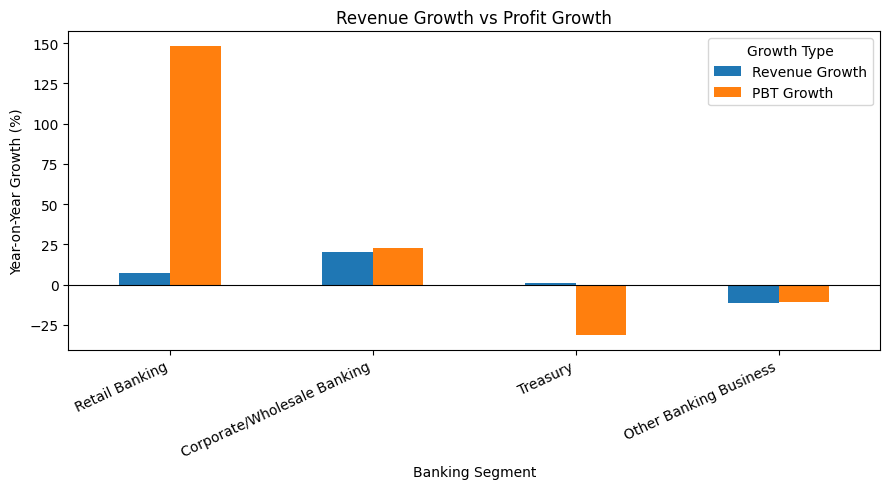

                             Revenue Growth  PBT Growth
segment                                                
Retail Banking                         7.40      148.32
Corporate/Wholesale Banking           20.00       22.69
Treasury                               0.80      -31.34
Other Banking Business               -11.64      -10.62


In [ ]:

growth = q1[
    ["segment", "segment_revenue_yoy_pct", "segment_pbt_yoy_pct"]
].copy()

growth = growth.set_index("segment")

growth.columns = ["Revenue Growth", "PBT Growth"]

ax = growth.plot(kind="bar", figsize=(9, 5))

ax.axhline(0, linewidth=0.8, color="black")   # zero line, kept out of the legend
ax.set_title("Revenue Growth vs Profit Growth")
ax.set_xlabel("Banking Segment")
ax.set_ylabel("Year-on-Year Growth (%)")
ax.legend(title="Growth Type")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(growth.round(2))

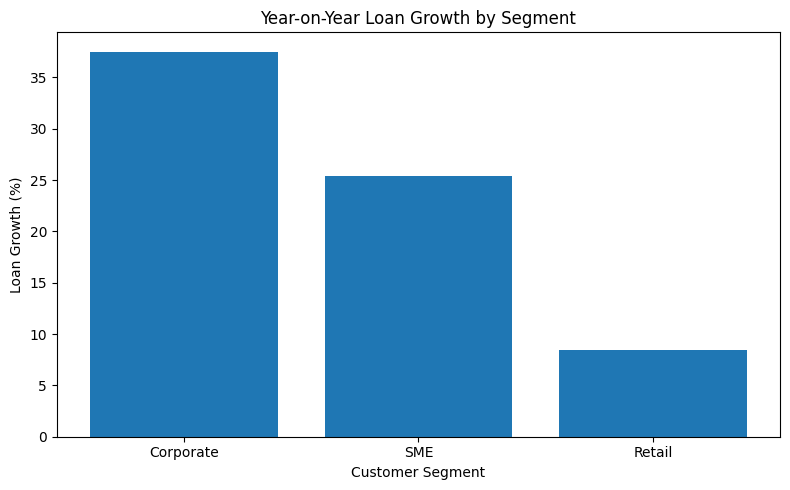

  customer_segment  jun_2025_cr  jun_2026_cr  yoy_growth_pct
1        Corporate       315892       434392           37.51
2              SME       120872       151619           25.44
3           Retail       622960       675546            8.44


In [ ]:
loan_data = loans[
    (loans["category"] == "Loans") &
    (loans["customer_segment"] != "Total")
].copy()

loan_data = loan_data.sort_values("yoy_growth_pct", ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(loan_data["customer_segment"], loan_data["yoy_growth_pct"])

plt.title("Year-on-Year Loan Growth by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Loan Growth (%)")
plt.tight_layout()
plt.show()

print(loan_data[
    ["customer_segment", "jun_2025_cr",
     "jun_2026_cr", "yoy_growth_pct"]
].round(2))

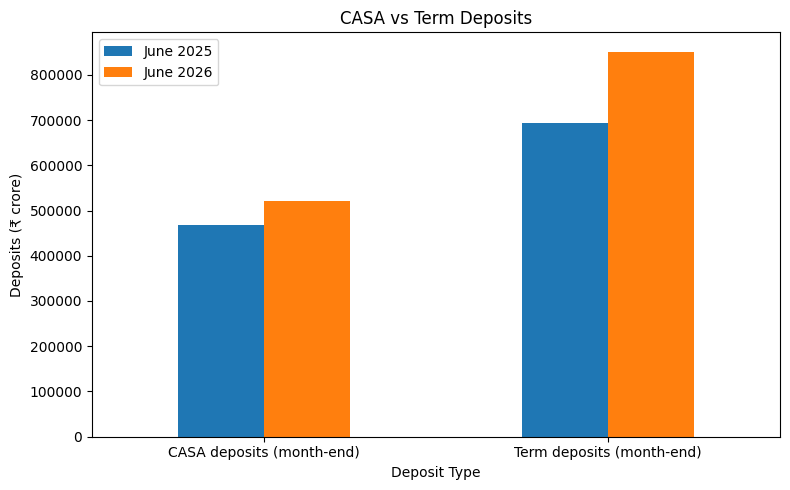

                           jun_2025_cr  jun_2026_cr  yoy_growth_pct
line_item                                                          
CASA deposits (month-end)       468166       521698           11.43
Term deposits (month-end)       693449       851238           22.75


In [ ]:
deposit_data = loans[
    (loans["category"] == "Deposits") &
    (loans["line_item"].isin([
        "CASA deposits (month-end)",
        "Term deposits (month-end)"
    ]))
].copy()

deposit_data = deposit_data.set_index("line_item")

deposit_data[["jun_2025_cr", "jun_2026_cr"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("CASA vs Term Deposits")
plt.xlabel("Deposit Type")
plt.ylabel("Deposits (₹ crore)")
plt.xticks(rotation=0)
plt.legend(["June 2025", "June 2026"])
plt.tight_layout()
plt.show()

print(deposit_data[
    ["jun_2025_cr", "jun_2026_cr", "yoy_growth_pct"]
].round(2))

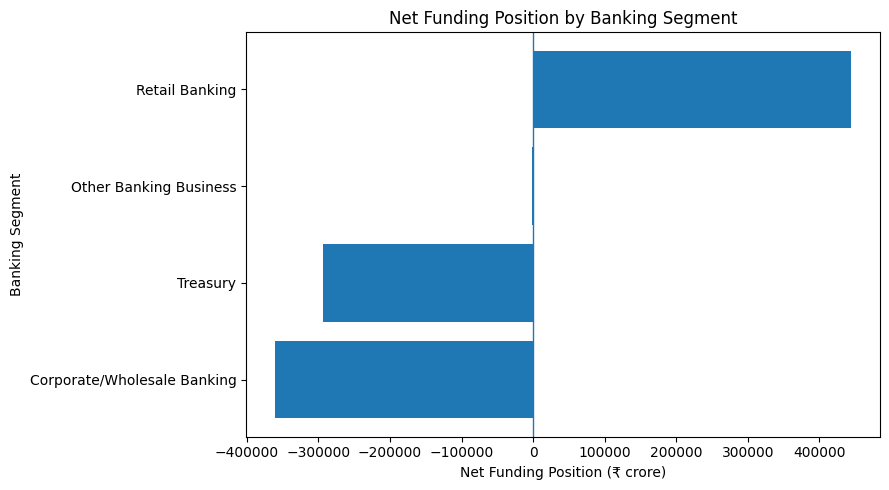

                       segment  net_funding_position_cr
1  Corporate/Wholesale Banking               -360792.35
0                     Treasury               -294096.61
5       Other Banking Business                 -1027.77
2               Retail Banking                444614.54


In [ ]:
funding = q1[
    ["segment", "net_funding_position_cr"]
].sort_values("net_funding_position_cr")

plt.figure(figsize=(9, 5))
plt.barh(funding["segment"], funding["net_funding_position_cr"])

plt.axvline(0, linewidth=1)
plt.title("Net Funding Position by Banking Segment")
plt.xlabel("Net Funding Position (₹ crore)")
plt.ylabel("Banking Segment")
plt.tight_layout()
plt.show()

print(funding.round(2))

                               line_item    Q1FY27    Q1FY26  Growth (%)
0                Interest earned (total)  33985.63  31063.51        9.41
7                      Interest expended  19339.53  17503.76       10.49
14                     Profit before tax   9436.56   7567.50       24.70
16                            Net profit   7113.92   5806.14       22.52
17  Net interest income (derived: 1 - 4)  14646.10  13559.75        8.01


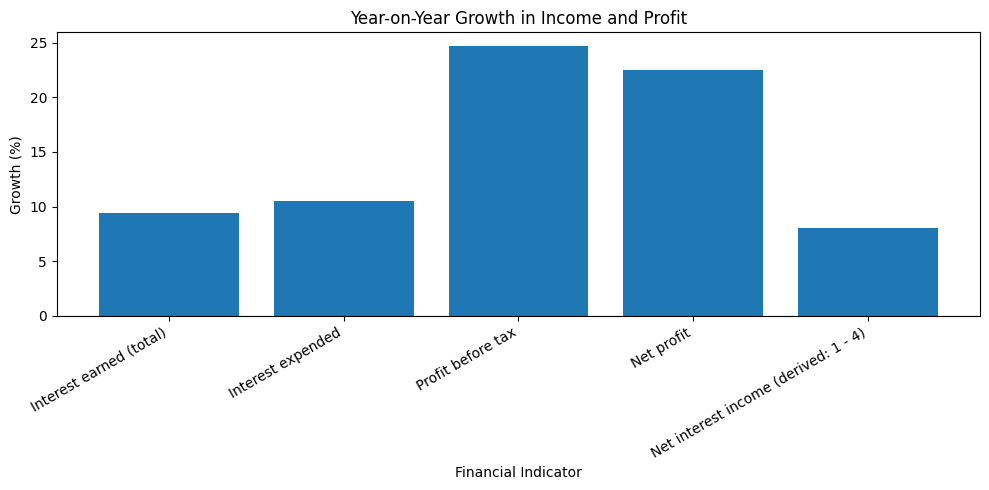

In [ ]:

# Loading the income statement
income = pd.read_csv(glob.glob("*03_income_statement_standalone*")[0])

# Selecting important financial indicators
metrics = [
    "Interest earned (total)",
    "Interest expended",
    "Net interest income (derived: 1 - 4)",
    "Profit before tax",
    "Net profit"
]

data = income[income["line_item"].isin(metrics)].copy()

# Comparing year-on-year growth
data = data[["line_item", "Q1FY27", "Q1FY26"]].copy()

data["Growth (%)"] = (
    (data["Q1FY27"] - data["Q1FY26"]) /
    data["Q1FY26"] * 100
)

print(data.round(2))

#  Growth rates plotting
plt.figure(figsize=(10, 5))

plt.bar(data["line_item"], data["Growth (%)"])

plt.title("Year-on-Year Growth in Income and Profit")
plt.xlabel("Financial Indicator")
plt.ylabel("Growth (%)")
plt.xticks(rotation=30, ha="right")
plt.axhline(0, linewidth=0.8)

plt.tight_layout()
plt.show()

                                            line_item  Q1FY27  Q1FY26
19  Cost-to-income ratio % (derived: opex / operat...   45.47   44.69
20      Provisions as % of operating profit (derived)   19.06   34.28


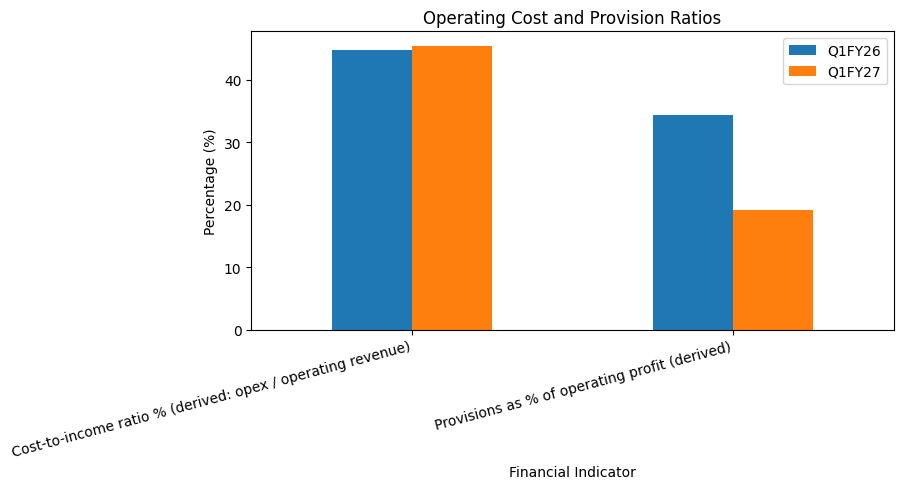

In [ ]:
income = pd.read_csv(glob.glob("*03_income_statement_standalone*")[0])

metrics = [
    "Cost-to-income ratio % (derived: opex / operating revenue)",
    "Provisions as % of operating profit (derived)"
]

data = income[income["line_item"].isin(metrics)].copy()

print(data[["line_item", "Q1FY27", "Q1FY26"]].round(2))

data = data.set_index("line_item")[["Q1FY26", "Q1FY27"]]

data.plot(kind="bar", figsize=(9, 5))

plt.title("Operating Cost and Provision Ratios")
plt.xlabel("Financial Indicator")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=15, ha="right")
plt.legend(["Q1FY26", "Q1FY27"])

plt.tight_layout()
plt.show()

metric  Gross NPA ratio  Net NPA ratio
period                                
Q1FY26             1.57           0.45
Q4FY26             1.23           0.37
Q1FY27             1.28           0.39


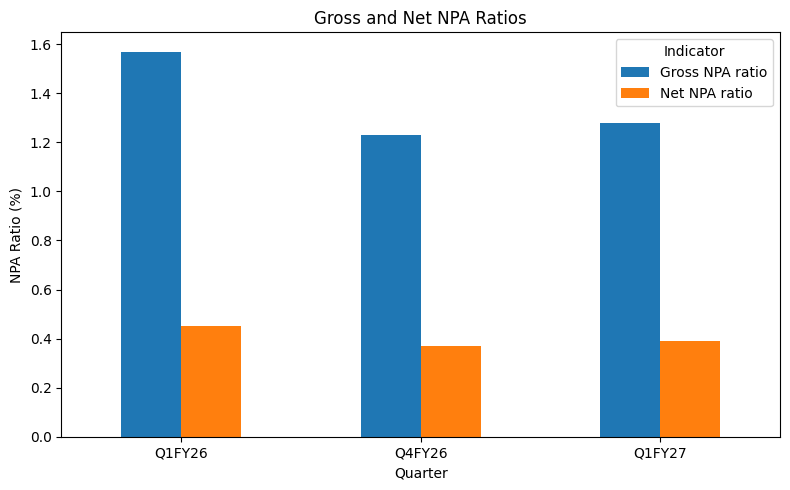

In [ ]:
kpis = pd.read_csv(glob.glob("*05_kpis_by_customer_segment*")[0])

metrics = [
    "Gross NPA ratio",
    "Net NPA ratio"
]

data = kpis[
    (kpis["metric"].isin(metrics)) &
    (kpis["period"].isin(["Q1FY26", "Q4FY26", "Q1FY27"])) &
    (kpis["customer_segment"] == "Bank")
].copy()

pivot = data.pivot_table(
    index="period",
    columns="metric",
    values="value",
    aggfunc="first"
)


pivot = pivot.reindex(["Q1FY26", "Q4FY26", "Q1FY27"])

print(pivot.round(2))

pivot.plot(kind="bar", figsize=(8, 5))

plt.title("Gross and Net NPA Ratios")
plt.xlabel("Quarter")
plt.ylabel("NPA Ratio (%)")
plt.xticks(rotation=0)
plt.legend(title="Indicator")

plt.tight_layout()
plt.show()

   period  total_segment_revenue_cr  less_inter_segment_revenue_cr  \
0  Q1FY27                  61839.54                       21118.49   
2  Q1FY26                  56915.50                       18593.93   

   income_from_operations_cr  Internal Revenue Share (%)  
0                   40721.05                       34.15  
2                   38321.57                       32.67  


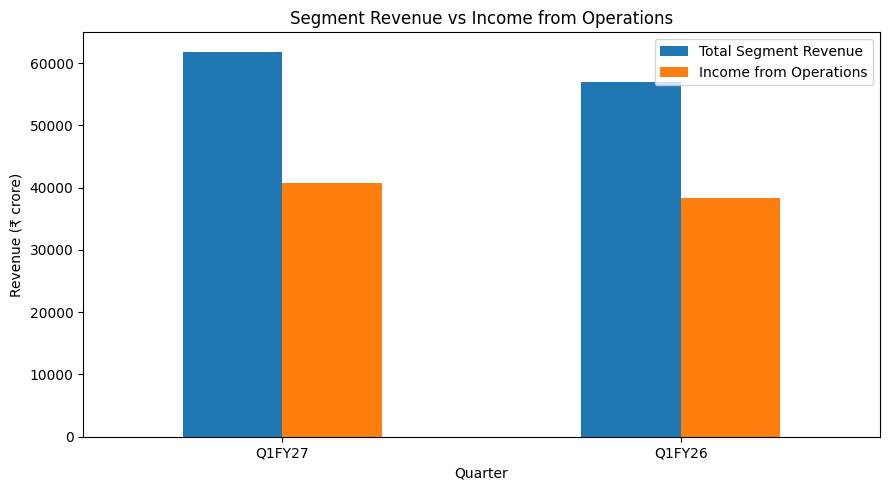

In [ ]:
recon = pd.read_csv(
    glob.glob("*01b_segment_totals_reconciliation*")[0]
)

recon = recon[recon["entity"] == "Standalone"].copy()

# Focusing on Q1FY26 and Q1FY27
recon = recon[
    recon["period"].isin(["Q1FY26", "Q1FY27"])
].copy()

recon["Internal Revenue Share (%)"] = (
    recon["less_inter_segment_revenue_cr"] /
    recon["total_segment_revenue_cr"] * 100
)

result = recon[
    [
        "period",
        "total_segment_revenue_cr",
        "less_inter_segment_revenue_cr",
        "income_from_operations_cr",
        "Internal Revenue Share (%)"
    ]
]

print(result.round(2))

plot_data = recon.set_index("period")[
    [
        "total_segment_revenue_cr",
        "income_from_operations_cr"
    ]
]

plot_data.plot(kind="bar", figsize=(9, 5))

plt.title("Segment Revenue vs Income from Operations")
plt.xlabel("Quarter")
plt.ylabel("Revenue (₹ crore)")
plt.xticks(rotation=0)
plt.legend(["Total Segment Revenue", "Income from Operations"])

plt.tight_layout()
plt.show()